In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats

In [4]:
air = pd.read_csv("https://data.cityofchicago.org/api/v3/views/rtmx-vkjr/export.csv?accessType=DOWNLOAD&app_token=bHWsGtRFRP9x8Hl8lYivqM1hQ")

In [5]:
air.head()

,datasourceid,outputfrequency,startofperiod,sensor_name,atmPressure24HourMean.raw,atmPressure24HourMean.value,bcAllSources24HourMean.raw,bcAllSources24HourMean.value,bcBiomass24HourMean.raw,bcBiomass24HourMean.value,...,temperatureInternal24HourMean.raw,temperatureInternal24HourMean.value,windDirection24HourMean.raw,windDirection24HourMean.value,windSpeed24HourMean.raw,windSpeed24HourMean.value,latitude,longitude,location,record_id
0,DEYGE9157,day,10/12/2025 12:00:00 AM,South Deering 10,NaN,NaN,NaN,NaN,NaN,NaN,...,15.66,15.66,NaN,NaN,NaN,NaN,41.701403,-87.570391,POINT (-87.5703907 41.7014031),DEYGE9157_2025-10-12
1,DEYGE9157,day,10/10/2025 12:00:00 AM,South Deering 10,NaN,NaN,NaN,NaN,NaN,NaN,...,14.09,14.09,NaN,NaN,NaN,NaN,41.701403,-87.570391,POINT (-87.5703907 41.7014031),DEYGE9157_2025-10-10
2,DWGYM0810,day,03/31/2026 12:00:00 AM,Avalon Park 1,NaN,NaN,NaN,NaN,NaN,NaN,...,19.16,19.16,NaN,NaN,NaN,NaN,41.750521,-87.585793,POINT (-87.58579258993602 41.7505205),DWGYM0810_2026-03-31
3,DVYCN4987,day,09/05/2026 12:00:00 AM,Mayfair Collocation 2,NaN,NaN,NaN,NaN,NaN,NaN,...,27.67,27.67,NaN,NaN,NaN,NaN,41.964742,-87.749434,POINT (-87.749434 41.964742),DVYCN4987_2026-09-05
4,DWGYM0810,day,04/03/2026 12:00:00 AM,Avalon Park 1,NaN,NaN,NaN,NaN,NaN,NaN,...,13.56,13.56,NaN,NaN,NaN,NaN,41.750521,-87.585793,POINT (-87.58579258993602 41.7505205),DWGYM0810_2026-04-03


In [6]:
air.shape

(126151, 46)

In [8]:
air_columns = [
    "datasourceid",
    "startofperiod",
    "sensor_name",
    "no2Conc24HourMean.raw",
    "no2Conc24HourMean.value",
    "pm2_5ConcMass24HourMean.raw",
    "pm2_5ConcMass24HourMean.value",
    "pm2_5ConcMass24HourMeanUsEpaAqi.raw",
    "pm2_5ConcMass24HourMeanUsEpaAqi.value",
    "pm2_5ConcNum24HourMean.raw",
    "pm2_5ConcNum24HourMean.value",
    "latitude",
    "longitude",
    "location",
    "record_id"
]
air_select_cols = air[air_columns].dropna() # keep only selected columns above and drop all rows with any null values

In [9]:
air_select_cols.shape

(124339, 15)

In [20]:
# setup
pm = 'pm2_5ConcMass24HourMean.value'
no2 = 'no2Conc24HourMean.value'

mean_agg = (
    air_select_cols
    .groupby("sensor_name", as_index=False)
    .agg(
        avg_pm2_5=(pm, "mean"),
        avg_no2=(no2, "mean"),
        latitude=("latitude", "first"),
        longitude=("longitude", "first"),
    )
    .sort_values("avg_pm2_5", ascending=False)
    .reset_index(drop=True)
)

In [21]:
mean_agg.head()

,sensor_name,avg_pm2_5,avg_no2,latitude,longitude
0,Avalon Park 1,16.860706,13.502725,41.750521,-87.585793
1,Austin 4,13.433318,17.457500,41.878702,-87.753153
2,Portage Park 5,12.991906,15.683309,41.949009,-87.762782
3,North Lawndale 5,12.829515,18.474665,41.852847,-87.736358
4,New City 3,12.716804,25.903470,41.801766,-87.635928


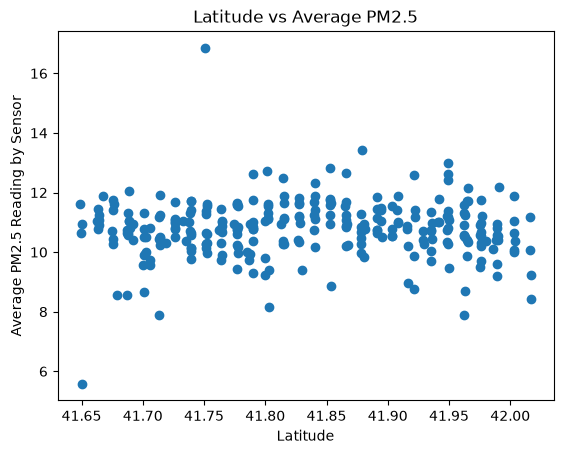

In [47]:
# latitude scatterplot
plt.scatter(mean_agg['latitude'], mean_agg['avg_pm2_5'])
plt.title('Latitude vs Average PM2.5')
plt.ylabel('Average PM2.5 Reading by Sensor')
plt.xlabel('Latitude')
plt.show()

In [54]:
result = scipy.stats.pearsonr(mean_agg['latitude'], mean_agg['avg_pm2_5'])
ci = result.confidence_interval(confidence_level=0.95)
print(f"Pearson r: {result.statistic:.4f}")
print(f"p-value: {result.pvalue:.4f}")
print(f"95% CI: [{ci.low:.4f}, {ci.high:.4f}]")

Pearson r: 0.0115
p-value: 0.8461
95% CI: [-0.1046, 0.1273]


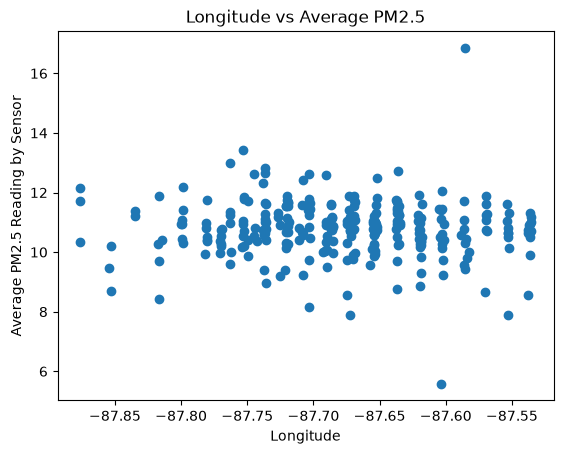

In [49]:
# longitude scatterplot
plt.scatter(mean_agg['longitude'], mean_agg['avg_pm2_5'])
plt.title('Longitude vs Average PM2.5')
plt.ylabel('Average PM2.5 Reading by Sensor')
plt.xlabel('Longitude')
plt.show()

In [55]:
result = scipy.stats.pearsonr(mean_agg['longitude'], mean_agg['avg_pm2_5'])
ci = result.confidence_interval(confidence_level=0.95)
print(f"Pearson r: {result.statistic:.4f}")
print(f"p-value: {result.pvalue:.4f}")
print(f"95% CI: [{ci.low:.4f}, {ci.high:.4f}]")

Pearson r: -0.0494
p-value: 0.4054
95% CI: [-0.1644, 0.0670]


**Findings**: The two scatterplots above show no linear correlation between average PM2.5 sensor reading and latitude or longitude. 

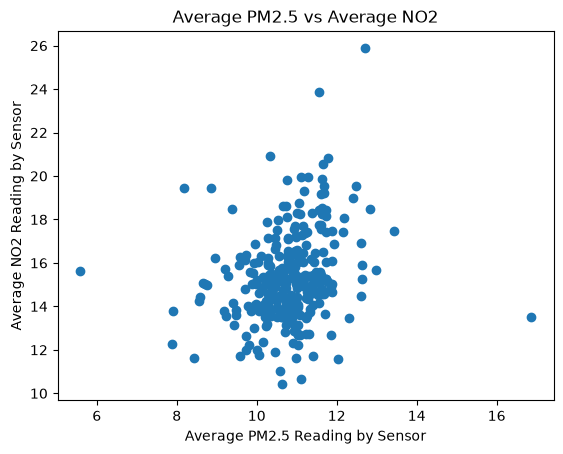

In [22]:
# avg pm2.5 vs avg no2
plt.scatter(mean_agg['avg_pm2_5'], mean_agg['avg_no2'])
plt.title('Average PM2.5 vs Average NO2')
plt.xlabel('Average PM2.5 Reading by Sensor')
plt.ylabel('Average NO2 Reading by Sensor')
plt.show()

In [56]:
result = scipy.stats.pearsonr(mean_agg['avg_pm2_5'], mean_agg['avg_no2'])
ci = result.confidence_interval(confidence_level=0.95)
print(f"Pearson r: {result.statistic:.4f}")
print(f"p-value: {result.pvalue:.4f}")
print(f"95% CI: [{ci.low:.4f}, {ci.high:.4f}]")

Pearson r: 0.2248
p-value: 0.0001
95% CI: [0.1118, 0.3322]


In [35]:
mean_agg.sort_values(by="avg_no2", inplace=True, ascending=False)
mean_agg.head() # top 5 highest

,sensor_name,avg_pm2_5,avg_no2,latitude,longitude
4,New City 3,12.716804,25.903470,41.801766,-87.635928
50,Near West Side 4,11.558801,23.856916,41.865238,-87.635227
212,Schiller Park Collocation 1,10.328919,20.908324,41.965175,-87.876252
24,South Lawndale 1,11.771796,20.834191,41.852921,-87.703111
37,Brighton Park 3,11.645837,20.532233,41.815056,-87.703197


In [36]:
mean_agg.tail() # bottom 5 

,sensor_name,avg_pm2_5,avg_no2,latitude,longitude
118,Jefferson Park 2,10.981527,11.607763,41.976053,-87.762680
14,Pullman 4,12.043939,11.558906,41.688426,-87.602561
180,West Ridge 5,10.581495,11.036593,41.989108,-87.707949
94,Lower West Side 5,11.097153,10.671134,41.840770,-87.686318
176,Hegewisch 4,10.629107,10.442832,41.649651,-87.552766


**Finding**: The sensors with the top 5 highest average NO2 readings are located near major transportation and/or industrial corridors by inspection on Google Maps.
* New City 3 - major railroad hub, I-90, southside
* Near West Side 4 - Metra, BNSF, and Amtrak railroad hub (Canal and Roosevelt)
* Schiller Park Collocation 1 - technically not in the city, but between Mannheim Rd and Tri-State Tollway next to O'Hare Airport 
* South Lawndale 1 - next to rail
* Brighton Park 3 - Archer and Kedzie, also next to railroad hub

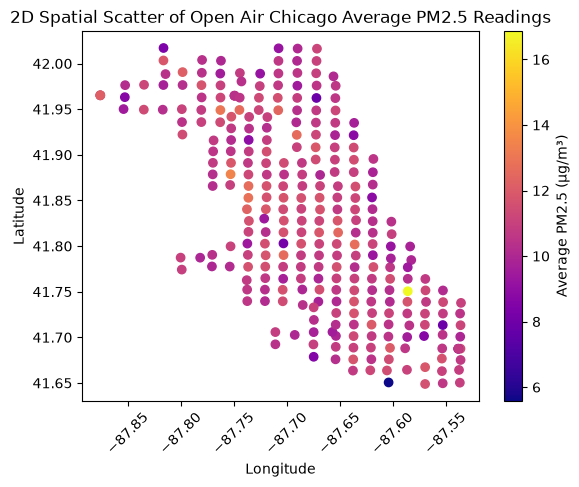

In [58]:
# 2D spatial scatter
scatter_2d = plt.scatter(x=mean_agg['longitude'], y=mean_agg['latitude'], c=mean_agg['avg_pm2_5'], cmap='plasma')
plt.colorbar(scatter_2d, label='Average PM2.5 (μg/m³)')
plt.title('2D Spatial Scatter of Open Air Chicago Average PM2.5 Readings')
plt.xticks(rotation=45)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.savefig('2d_spatial_scatter.jpg')
plt.show()